# TP2 : traitement d'images par approches variationnelles

**Modélisation pour le traitement d'images**, Université de Bordeaux

**Travail réalisé par :** Younes Bouhoreira, M'Hamed Soilihi, Lucas Stepanova

In [1]:
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from scipy.signal import convolve2d
from scipy.fft import dctn, idctn

## 1

Sur papier : voir `TP2_questions_papier.pdf`.

## 2

Sur papier : voir `TP2_questions_papier.pdf`.

# Débruitage par approches variationnelles

In [2]:
def scalar_product(u, v):
    if u.ndim > 2:
        return np.sum(u * v, axis=0)
    else:
        return np.sum(u * v)

def norm(u):
    return np.sqrt(scalar_product(u, u))

In [3]:
def gradient(u):
    m, n = u.shape
    grad_u = np.zeros((2, m, n))
    
    grad_u[0, :-1, :] = u[1:] - u[:-1]
    
    grad_u[1, :, :-1] = u[:, 1:] - u[:, :-1]
    
    return grad_u

In [4]:
def div(p):
    m, n = p.shape[1:]
    
    div_1 = np.zeros((m, n))
    div_1[:-1, :] = p[0, :-1, :]
    div_1[1:, :] -= p[0, :-1, :]
    
    div_2 = np.zeros((m, n))
    div_2[:, :-1] = p[1, :, :-1]
    div_2[:, 1:] -= p[1, :, :-1]
    
    return div_1 + div_2

In [5]:
def laplacian(u):
    return div(gradient(u))

In [6]:
# Test : div est l'opposé de l'adjoint de gradient,  <grad u, p> = -<u, div p>
rng = np.random.default_rng(0)
u_test, p_test = rng.standard_normal((40, 50)), rng.standard_normal((2, 40, 50))
assert abs(np.sum(gradient(u_test) * p_test) + np.sum(u_test * div(p_test))) < 1e-9
assert np.allclose(laplacian(np.ones((40, 50))), 0)   # le laplacien d'une constante est nul
print("gradient / div : OK")

gradient / div : OK


#### Préparation des images

In [7]:
def load_img(fname, dirname='images/'):
    Im_PIL = Image.open(dirname + fname)
    return np.array(Im_PIL)

In [8]:
def add_gaussian_noise(I, s):
    m, n = I.shape
    
    I_out = I + s * np.random.randn(m, n)
    
    return I_out

In [9]:
# Load image
Im_data = load_img('cameraman.png', dirname='images/')

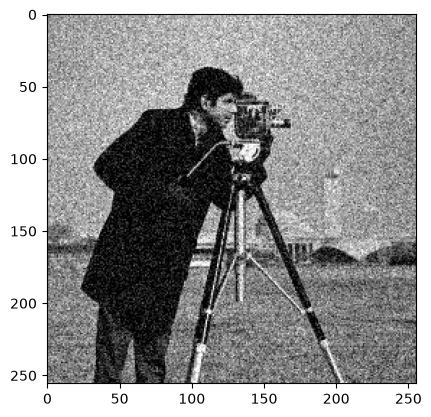

In [10]:
# Noise image (graine fixée pour des résultats reproductibles)
np.random.seed(0)
Im_noised = add_gaussian_noise(Im_data, s=30)

bounds = {'vmin': 0, 'vmax': 255}
plt.imshow(Im_noised, cmap='gray', **bounds)

plt.show()

#### Critère de convergence

In [11]:
def convergence_criteria(u0, u1, conv_crit):
    """
    Vérifie si la norme relative de la différence entre deux itérations
    est inférieure au seuil conv_crit.
    """
    err = norm(u1 - u0) / (norm(u0) + 1e-12)
    return err < conv_crit

def rmse(u, ref):
    return np.sqrt(np.mean((u - ref) ** 2))

## 3

In [12]:
def Denoise_Tikhonov(f, K, lamb, tau=None, conv_crit=1e-5):
    
    if tau is None:
        tau = 1.0 / (lamb + 4.0)
        
    u = f.astype(np.float64).copy()
    
    for k in range(K):
        u_prev = u
        
        # u^{k+1} = u^k + tau * (lamb * (f - u^k) + Delta u^k)
        u = u + tau * (lamb * (f - u) + laplacian(u))
        
        if convergence_criteria(u_prev, u, conv_crit):
            break
            
    return u

## 5.1
### Test de `Denoise_Tikhonov` 

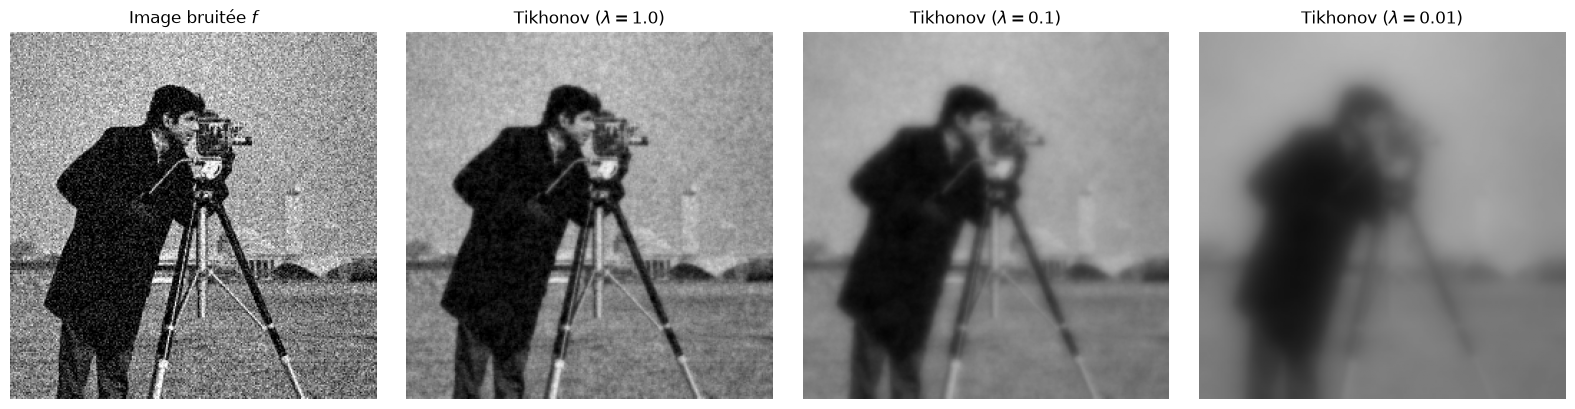

In [13]:
lambdas_tik = [1.0, 0.1, 0.01]
K_max = 1000

fig, axes = plt.subplots(1, len(lambdas_tik) + 1, figsize=(16, 4))
axes[0].imshow(Im_noised, cmap='gray', **bounds)
axes[0].set_title("Image bruitée $f$")
axes[0].axis('off')

for i, lamb in enumerate(lambdas_tik):
    u_tik = Denoise_Tikhonov(Im_noised, K=K_max, lamb=lamb)
    axes[i+1].imshow(u_tik, cmap='gray', **bounds)
    axes[i+1].set_title(f"Tikhonov ($\\lambda = {lamb}$)")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

Plus $\lambda$ est **grand**, plus $u_\lambda$ reste proche de $f$ : l'image est *moins* débruitée. Plus $\lambda$ est petit, plus la régularisation domine : le bruit disparaît, mais les contours deviennent flous.

## 4

In [14]:
def Denoise_weighted(f, K, lamb, tau, weight, conv_crit):
    """
    Boucle commune à Denoise_TV, Denoise_g1 et Denoise_g2 :
        u^{k+1} = u^k + tau * ( lamb * (f - u^k) + div( w * grad u^k ) ),   w = weight(|grad u^k|^2)
    Seul le poids w = phi'(xi) / xi change d'une méthode à l'autre.
    """
    f = f.astype(np.float64)
    u = f.copy()

    for k in range(K):
        u_prev = u

        grad = gradient(u)                                    # shape (2, m, n)
        w = weight(np.sum(grad**2, axis=0))                   # poids par pixel, shape (m, n)

        u = u + tau * (lamb * (f - u) + div(w * grad))

        if convergence_criteria(u_prev, u, conv_crit):
            break

    return u


def tv_flux(u, eps):
    """grad(u) / sqrt(||grad(u)||^2 + eps^2) : le flux de la TV lissée (utilisé aussi par Deconvolution_TV et Inpainting_TV)."""
    grad_u = gradient(u)
    return grad_u / np.sqrt(grad_u[0]**2 + grad_u[1]**2 + eps**2)


def Denoise_TV(f, K, lamb, eps=1.0, tau=0.1, conv_crit=1e-4):
    """TV lissée : w = 1 / sqrt(||grad u||^2 + eps^2)."""
    return Denoise_weighted(f, K, lamb, tau, lambda g2: 1.0 / np.sqrt(g2 + eps**2), conv_crit)

## 5.2
### Test de `Denoise_TV`

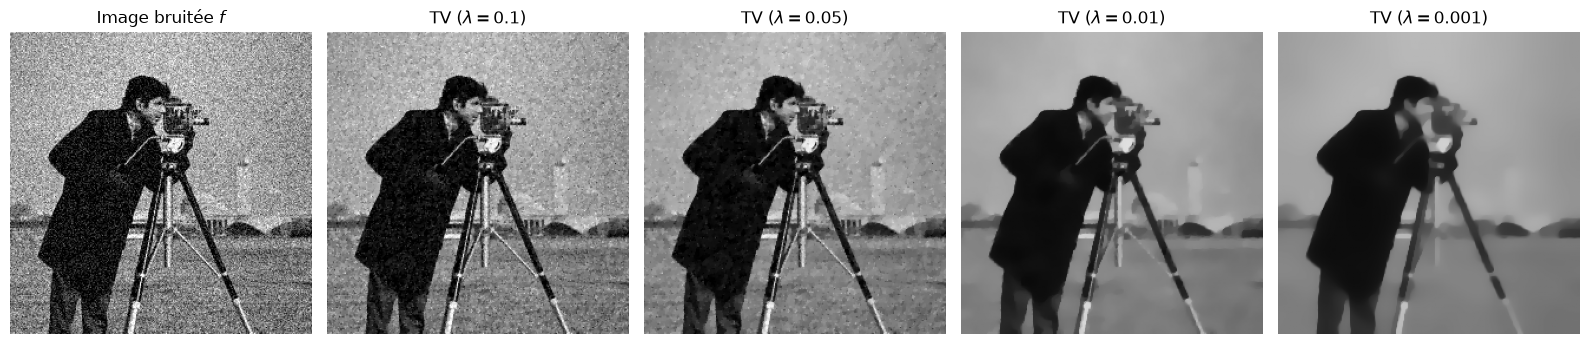

In [15]:
lambdas_tv = [0.1, 0.05, 0.01, 0.001]
K_max = 1000
eps = 1.0
tau_tv = 0.1  # Doit rester modéré pour garantir la stabilité numérique

fig, axes = plt.subplots(1, len(lambdas_tv) + 1, figsize=(16, 4))
axes[0].imshow(Im_noised, cmap='gray', **bounds)
axes[0].set_title("Image bruitée $f$")
axes[0].axis('off')

for i, lamb in enumerate(lambdas_tv):
    u_tv = Denoise_TV(Im_noised, K=K_max, lamb=lamb, eps=eps, tau=tau_tv)
    axes[i+1].imshow(u_tv, cmap='gray', **bounds)
    axes[i+1].set_title(f"TV ($\\lambda = {lamb}$)")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

Avec un $\lambda$ bien choisi, la TV lissée débruite mieux que Tikhonov (1.6) : les contours restent plus nets.

sigma=10 : Tikhonov lambda_opt=8.13 (RMSE 8.1) | TV lambda_opt=0.188 (RMSE 5.9)
sigma=20 : Tikhonov lambda_opt=2.45 (RMSE 12.4) | TV lambda_opt=0.071 (RMSE 9.1)
sigma=30 : Tikhonov lambda_opt=1.34 (RMSE 15.1) | TV lambda_opt=0.043 (RMSE 11.4)
sigma=50 : Tikhonov lambda_opt=0.55 (RMSE 18.6) | TV lambda_opt=0.016 (RMSE 15.1)


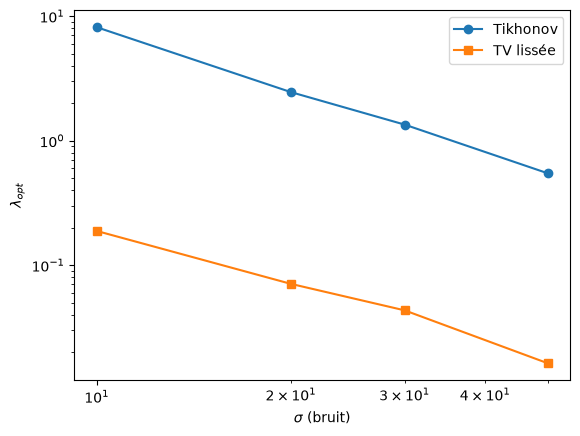

In [16]:
# Question 5 : évolution de lambda_opt avec le niveau de bruit
sigmas = [10, 20, 30, 50]
lambdas_opt_tik = np.geomspace(0.3, 20, 15)
lambdas_opt_tv = np.geomspace(0.01, 0.5, 9)
opt_tik, opt_tv = [], []

for s in sigmas:
    np.random.seed(0)
    f_s = add_gaussian_noise(Im_data, s)
    e_tik = [rmse(Denoise_Tikhonov(f_s, K=1000, lamb=l), Im_data) for l in lambdas_opt_tik]
    e_tv = [rmse(Denoise_TV(f_s, K=1000, lamb=l, conv_crit=0), Im_data) for l in lambdas_opt_tv]
    opt_tik.append(lambdas_opt_tik[np.argmin(e_tik)])
    opt_tv.append(lambdas_opt_tv[np.argmin(e_tv)])
    print(f"sigma={s} : Tikhonov lambda_opt={opt_tik[-1]:.2f} (RMSE {min(e_tik):.1f}) | TV lambda_opt={opt_tv[-1]:.3f} (RMSE {min(e_tv):.1f})")

plt.loglog(sigmas, opt_tik, 'o-', label='Tikhonov')
plt.loglog(sigmas, opt_tv, 's-', label='TV lissée')
plt.xlabel("$\\sigma$ (bruit)")
plt.ylabel("$\\lambda_{opt}$")
plt.legend()
plt.show()

**Évolution de $\lambda_{opt}$ avec le bruit.** Plus le bruit $\sigma$ est fort, plus $\lambda_{opt}$ (celui qui minimise le RMSE) est **petit** : on fait moins confiance à $f$ et on régularise davantage. Les $\lambda_{opt}$ de Tikhonov et de la TV ne sont pas dans la même plage (régularisation quadratique contre linéaire). Les valeurs sont celles de la grille testée.

## 6

In [17]:
def Denoise_Tikhonov_DFT(f, lamb):
    m, n = f.shape

    # 1. Grille des fréquences (p, q)
    p = np.arange(m)[:, None]  # shape (m, 1)
    q = np.arange(n)[None, :]  # shape (1, n)

    # 2. Valeurs propres / symbole de Fourier du laplacien discret
    # L_hat = 2*(cos(2*pi*p/m) - 1) + 2*(cos(2*pi*q/n) - 1)
    L_hat = -4.0 * (
        np.sin(np.pi * p / m) ** 2 + np.sin(np.pi * q / n) ** 2
    )  #

    # 3. FFT de l'image bruitée f
    f_hat = np.fft.fft2(f)

    # 4. Inversion dans le domaine fréquentiel
    u_hat = (lamb * f_hat) / (lamb - L_hat)

    # 5. Transformée inverse (partie réelle)
    u = np.real(np.fft.ifft2(u_hat))

    return u

def Denoise_Tikhonov_DCT(f, lamb):
    """
    Même filtre que (1.14), mais avec la DCT au lieu de la TFD.
    La DCT correspond aux bords de Neumann utilisés par gradient/div :
    elle donne exactement la limite de Denoise_Tikhonov, y compris aux bords.
    """
    m, n = f.shape
    p = np.arange(m)[:, None]
    q = np.arange(n)[None, :]
    L_hat = -4.0 * (np.sin(np.pi * p / (2 * m)) ** 2 + np.sin(np.pi * q / (2 * n)) ** 2)
    return idctn(lamb * dctn(f, norm='ortho') / (lamb - L_hat), norm='ortho')

### Test de `Denoise_Tikhonov_DFT` et `Denoise_Tikhonov_DCT` 

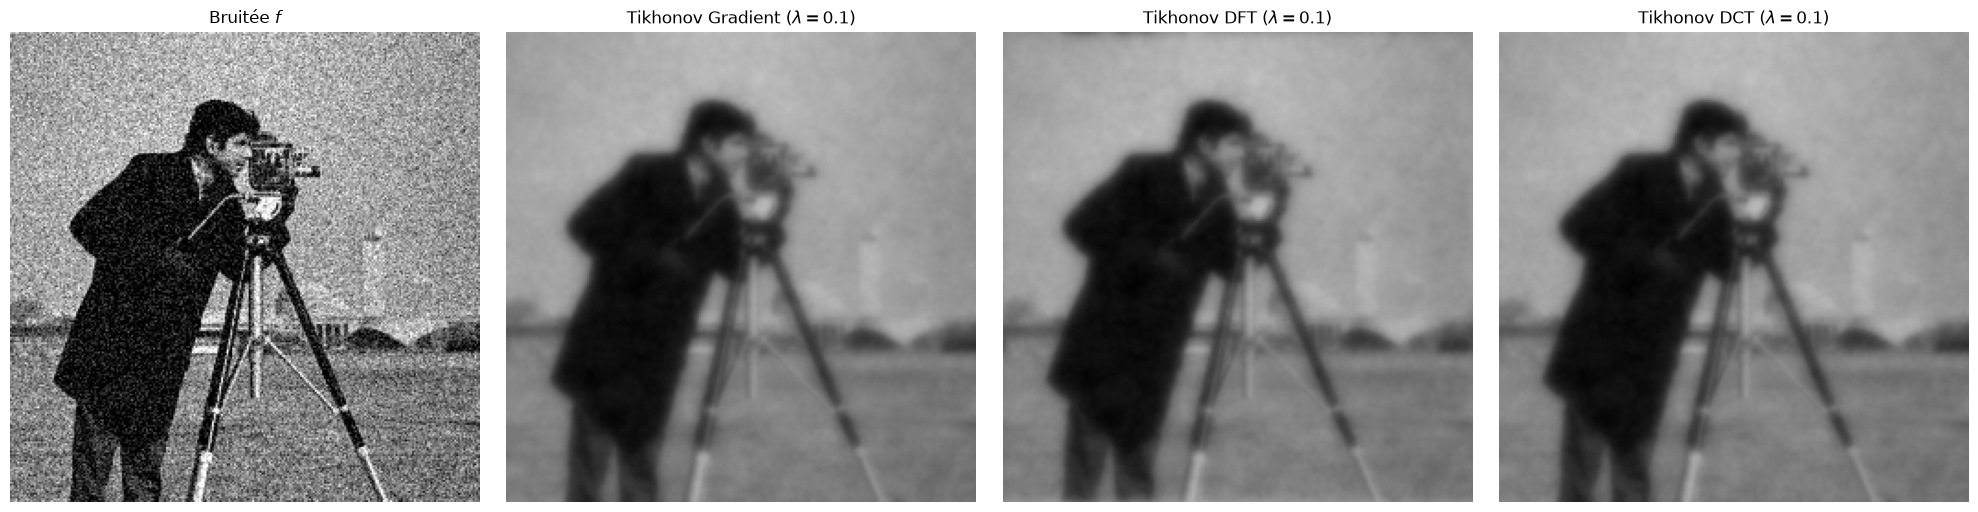

In [18]:
lamb = 0.1
u_tik_grad = Denoise_Tikhonov(Im_noised, K=1500, lamb=lamb)
u_tik_dft = Denoise_Tikhonov_DFT(Im_noised, lamb=lamb)
u_tik_dct = Denoise_Tikhonov_DCT(Im_noised, lamb=lamb)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(Im_noised, cmap='gray', **bounds)
axes[0].set_title('Bruitée $f$')
axes[0].axis('off')

axes[1].imshow(u_tik_grad, cmap='gray', **bounds)
axes[1].set_title(f'Tikhonov Gradient ($\\lambda = {lamb}$)')
axes[1].axis('off')

axes[2].imshow(u_tik_dft, cmap='gray', **bounds)
axes[2].set_title(f'Tikhonov DFT ($\\lambda = {lamb}$)')
axes[2].axis('off')

axes[3].imshow(u_tik_dct, cmap='gray', **bounds)
axes[3].set_title(f'Tikhonov DCT ($\\lambda = {lamb}$)')
axes[3].axis('off')

plt.tight_layout()
plt.show()

Les images sont floues : avec $\lambda = 0.1$ la régularisation domine et lisse beaucoup.

La TFD (1.14) suppose une image **périodique** (le bord gauche touche le bord droit), alors que `gradient`/`div` utilisent des bords de **Neumann**. Les deux résultats coïncident à l'intérieur, mais diffèrent nettement sur les bords (jusqu'à ~55 niveaux de gris). La DCT diagonalise le laplacien de Neumann : `Denoise_Tikhonov_DCT` donne exactement la limite de la descente de gradient (vérifié dans la cellule suivante).

In [19]:
# Tests : chaque solution vérifie sa condition d'optimalité  lamb * (u - f) - Delta u = 0
def laplacian_periodic(u):
    return (np.roll(u, 1, 0) + np.roll(u, -1, 0) + np.roll(u, 1, 1) + np.roll(u, -1, 1) - 4 * u)

res_dft = lamb * (u_tik_dft - Im_noised) - laplacian_periodic(u_tik_dft)   # TFD : bords périodiques
res_dct = lamb * (u_tik_dct - Im_noised) - laplacian(u_tik_dct)            # DCT : bords de Neumann
assert np.abs(res_dft).max() < 1e-8, np.abs(res_dft).max()
assert np.abs(res_dct).max() < 1e-8, np.abs(res_dct).max()
print("Écart DFT / DCT : intérieur", np.abs(u_tik_dft - u_tik_dct)[20:-20, 20:-20].max(),
      "| bords", np.abs(u_tik_dft - u_tik_dct).max())

Écart DFT / DCT : intérieur 0.08405786944953775 | bords 55.42354392954309


## 7

Sur papier : voir `TP2_questions_papier.pdf`.

# Extensions : déconvolution et inpainting

## 8

Sur papier : voir `TP2_questions_papier.pdf`.

#### Chargement des images

In [20]:
# Image : Parrot
Im_parrot = load_img('Im1.png')
Mask_parrot = load_img('Im1_mask.png')

# Image : Beach
Im_beach = load_img('Im2.png')
Mask_beach = load_img('Im2_mask.png')

# Image : Mystery text
Im_mystery = load_img('Im3.png')
Mask_mystery = load_img('Im3_mask.png')

In [21]:
def gaussian_kernel(size, sigma):
    variance = sigma**2
    half_size = size // 2
    
    range_matrix = np.arange(- half_size, half_size + 1)
    X, Y = np.meshgrid(range_matrix, range_matrix)
    
    return np.exp(- (X**2 + Y**2) / (2 * variance)) / (2 * np.pi * variance)

In [22]:
def convolve(f, G):
    return convolve2d(f, G, mode='same', boundary='symm')

## 9

In [23]:
def Deconvolution_TV(f, G, tau, eps, K, lamb):
    u = f.astype(np.float64).copy()
    
    for k in range(K):
        # Terme d'attache aux données : G * (f - G * u)
        Gu = convolve(u, G)
        data_term = convolve(f - Gu, G)
        
        # Terme de régularisation TV : div( grad(u) / sqrt(||grad(u)||^2 + eps^2) )
        reg_term = div(tv_flux(u, eps))
        
        # Schéma de descente de gradient (équation 2.18)
        u = u + tau * (lamb * data_term + reg_term)
        
    return u

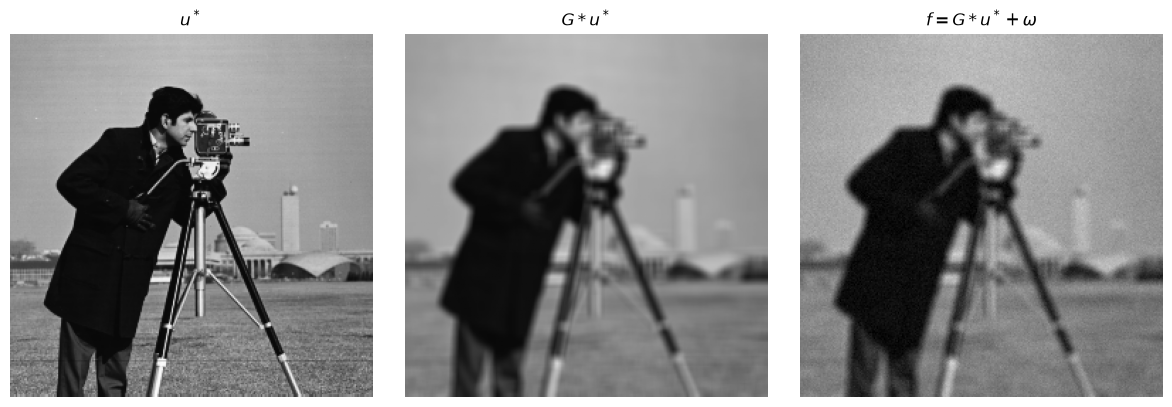

In [24]:
np.random.seed(0)

# Noyau gaussien normalisé (somme = 1) pour ne pas assombrir l'image
G = gaussian_kernel(size=7, sigma=5)
G = G / G.sum()

Im_convolved = convolve(Im_data.astype(np.float64), G)        # G * u*
Im_convolved_noised = add_gaussian_noise(Im_convolved, s=5)   # f = G * u* + w

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, title in zip(axes,
                         [Im_data, Im_convolved, Im_convolved_noised],
                         ["$u^*$", "$G * u^*$", "$f = G * u^* + \\omega$"]):
    ax.imshow(im, cmap='gray', **bounds)
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 12.1
### Test de `Deconvolution_TV`

RMSE de f : 21.0 | flou seul : 20.4
lambda=0.1 : RMSE 18.8 | résidu 6.1
lambda=1.0 : RMSE 15.2 | résidu 5.0
lambda=2.0 : RMSE 14.3 | résidu 4.9
lambda=5.0 : RMSE 14.5 | résidu 4.6
lambda=20.0 : RMSE 23.8 | résidu 4.1


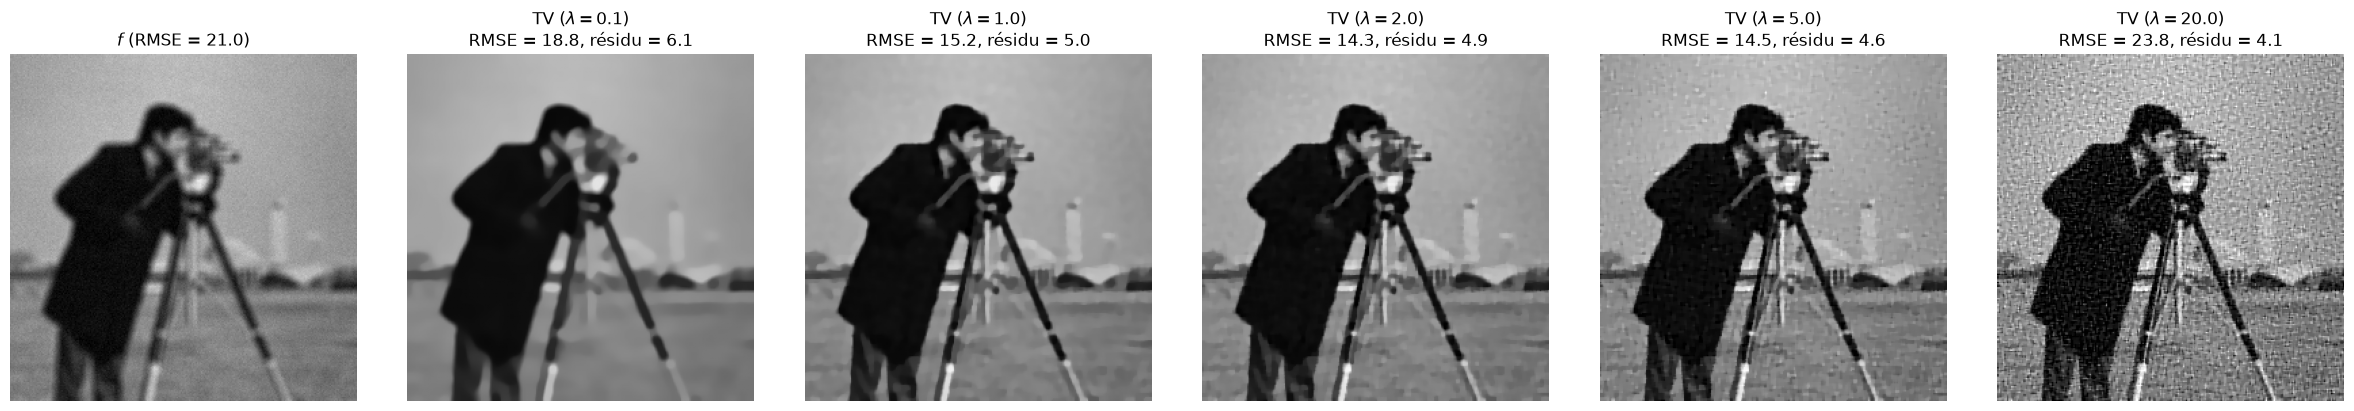

lambda=20.0, K=100 : RMSE 17.0
lambda=20.0, K=500 : RMSE 23.8
lambda=20.0, K=2000 : RMSE 31.7


In [25]:
lambdas_deconv = [0.1, 1.0, 2.0, 5.0, 20.0]
K_deconv = 500
eps = 1.0

def residu(u):
    """||G*u - f|| / sqrt(mn), à comparer au niveau de bruit sigma = 5."""
    return np.linalg.norm(convolve(u, G) - Im_convolved_noised) / np.sqrt(u.size)

fig, axes = plt.subplots(1, len(lambdas_deconv) + 1, figsize=(24, 4))
axes[0].imshow(Im_convolved_noised, cmap='gray', **bounds)
axes[0].set_title(f"$f$ (RMSE = {rmse(Im_convolved_noised, Im_data):.1f})")
axes[0].axis('off')
print(f"RMSE de f : {rmse(Im_convolved_noised, Im_data):.1f} | flou seul : {rmse(Im_convolved, Im_data):.1f}")

for i, lamb in enumerate(lambdas_deconv):
    tau = 1.0 / (lamb + 8.0 / eps)   # pas stable : tau < 2 / L
    u_deconv = Deconvolution_TV(Im_convolved_noised, G, tau=tau, eps=eps, K=K_deconv, lamb=lamb)
    print(f"lambda={lamb} : RMSE {rmse(u_deconv, Im_data):.1f} | résidu {residu(u_deconv):.1f}")
    axes[i+1].imshow(u_deconv, cmap='gray', **bounds)
    axes[i+1].set_title(f"TV ($\\lambda = {lamb}$)\nRMSE = {rmse(u_deconv, Im_data):.1f}, résidu = {residu(u_deconv):.1f}")
    axes[i+1].axis('off')

plt.tight_layout()
plt.show()

# Rôle de K pour lambda = 20
lamb = 20.0
for K in (100, 500, 2000):
    u_K = Deconvolution_TV(Im_convolved_noised, G, tau=1.0 / (lamb + 8.0 / eps), eps=eps, K=K, lamb=lamb)
    print(f"lambda={lamb}, K={K} : RMSE {rmse(u_K, Im_data):.1f}")

**Commentaires (déconvolution TV).** $f$ a un RMSE de 21,0 par rapport à $u^*$ (20,4 pour le flou seul). On regarde aussi le résidu $\|G*u-f\|/\sqrt{mn}$, à comparer au niveau de bruit $\sigma=5$ ($K=500$) :

| $\lambda$ | RMSE | résidu |
|---|---|---|
| 0.1 | 18,8 | 6,1 |
| 1 | 15,2 | 5,0 |
| 2 | 14,3 | 4,9 |
| 5 | 14,5 | 4,6 |
| 20 | **23,8** | 4,1 |

- **$\lambda$ petit (0.1)** : la TV domine, l'image est trop lisse et le résidu dépasse le bruit.
- **$\lambda$ entre 1 et 5** : bon compromis, les contours redeviennent nets. Le résidu est proche de $\sigma$.
- **$\lambda = 20$** : le résultat est **pire que l'image floue** (23,8 contre 21,0). Le résidu passe sous $\sigma$ : on ajuste $u$ au bruit. $G$ atténue les hautes fréquences, donc les inverser amplifie le bruit, et la TV ne pèse plus assez pour le retenir.
- **Rôle de $K$** : pour $\lambda=20$, le RMSE passe de 17,0 ($K=100$) à 23,8 ($K=500$) puis 31,7 ($K=2000$), alors que l'énergie continue de diminuer. La descente est donc stable (mais pas encore convergée) : c'est le minimiseur visé qui est mauvais pour ce $\lambda$, et s'arrêter tôt joue le rôle d'une régularisation.

## 10

In [26]:
def Inpainting_TV(f, M, tau, eps, K, lamb):
    f = f.astype(np.float64)
    M = (M > 0).astype(np.float64)   # normalise le masque en {0, 1} (accepte 0/255)
    u = f.copy()
    
    for k in range(K):
        # Terme d'attache aux données : M * (f - u)
        data_term = M * (f - u)
        
        # Terme de régularisation TV : div( grad(u) / sqrt(||grad(u)||^2 + eps^2) )
        reg_term = div(tv_flux(u, eps))
        
        # Schéma de descente de gradient (équation 2.20)
        u = u + tau * (lamb * data_term + reg_term)

    return u

## 12.2
### Test de `Inpainting_TV`

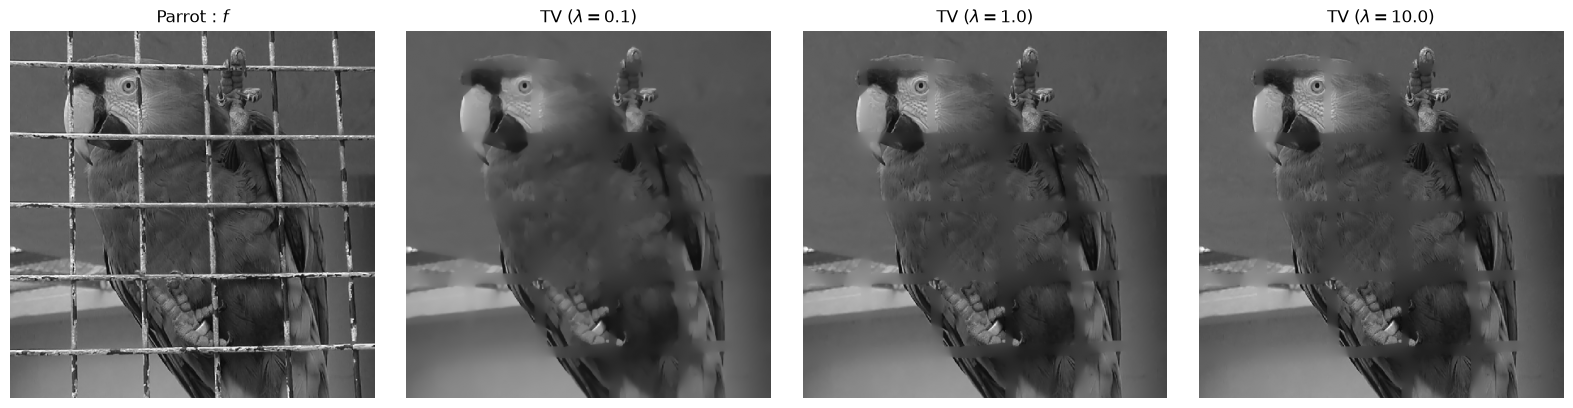

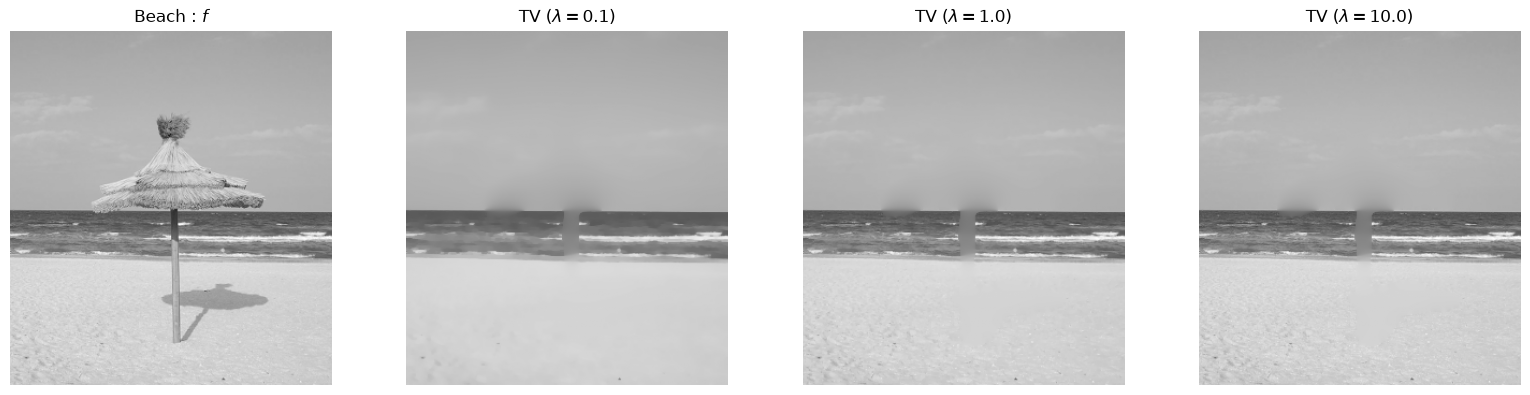

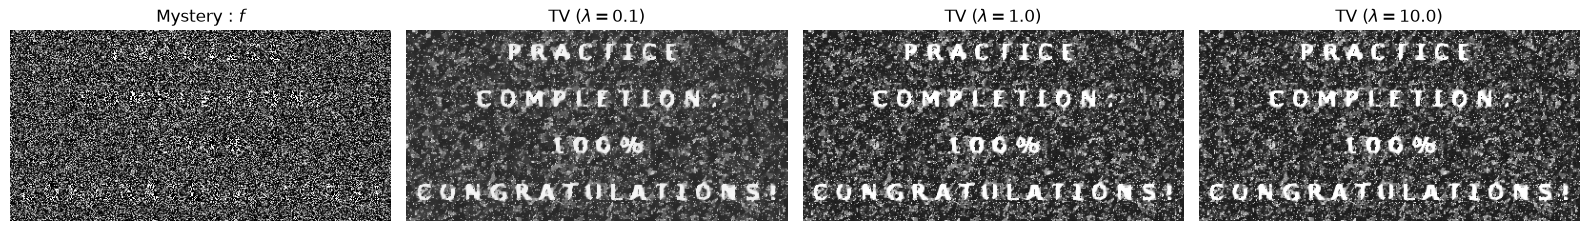

In [27]:
lambdas_inp_tv = [0.1, 1.0, 10.0]
K_inp_tv = 24000   # grand K : la diffusion TV est lente pour combler les trous (~6 min au total ; remplissage pas tout à fait convergé pour lambda = 10)
eps = 1.0

for name, Im, Mask in [("Parrot", Im_parrot, Mask_parrot),
                       ("Beach", Im_beach, Mask_beach),
                       ("Mystery", Im_mystery, Mask_mystery)]:
    fig, axes = plt.subplots(1, len(lambdas_inp_tv) + 1, figsize=(16, 4))
    axes[0].imshow(Im, cmap='gray', **bounds)
    axes[0].set_title(f"{name} : $f$")
    axes[0].axis('off')

    for i, lamb in enumerate(lambdas_inp_tv):
        u_inp = Inpainting_TV(Im, Mask, tau=1.8 / (lamb + 8.0 / eps), eps=eps, K=K_inp_tv, lamb=lamb)
        axes[i+1].imshow(u_inp, cmap='gray', **bounds)
        axes[i+1].set_title(f"TV ($\\lambda = {lamb}$)")
        axes[i+1].axis('off')

    plt.tight_layout()
    plt.show()

## 11

In [28]:
def Inpainting_Tikhonov(f, M, tau, K, lamb, conv_crit=1e-6):
    """
    Inpainting avec régularisation de Tikhonov (équation 2.20) :
        u^{k+1} = u^k + tau * ( lamb * (f - u^k) * M + Delta u^k )
    f : image partiellement observée
    M : masque (1 = pixel connu, 0 = pixel à reconstruire), accepte aussi 0/255
    tau : pas de temps (stable si tau < 2 / (lamb + 8), ex. 1 / (lamb + 4))
    """
    f = f.astype(np.float64)
    M = (M > 0).astype(np.float64)   # normalise le masque en {0, 1}

    u = f.copy()

    for k in range(K):
        u_prev = u

        # Attache aux données uniquement sur les pixels connus + diffusion isotrope
        u = u + tau * (lamb * (f - u) * M + laplacian(u))

        if convergence_criteria(u_prev, u, conv_crit):
            break

    return u

## 12.3
### Test de `Inpainting_Tikhonov`

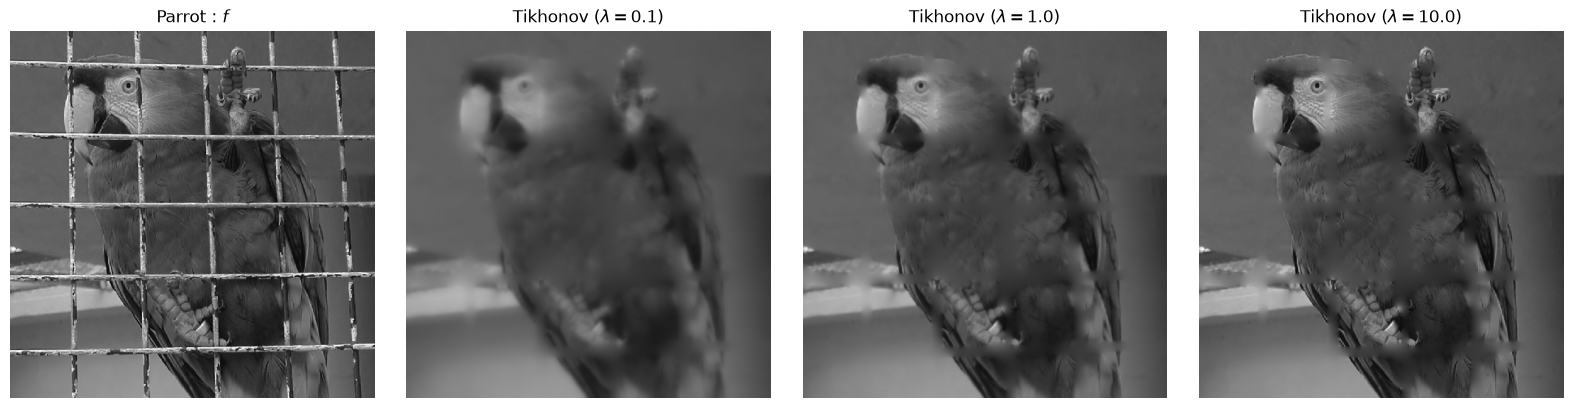

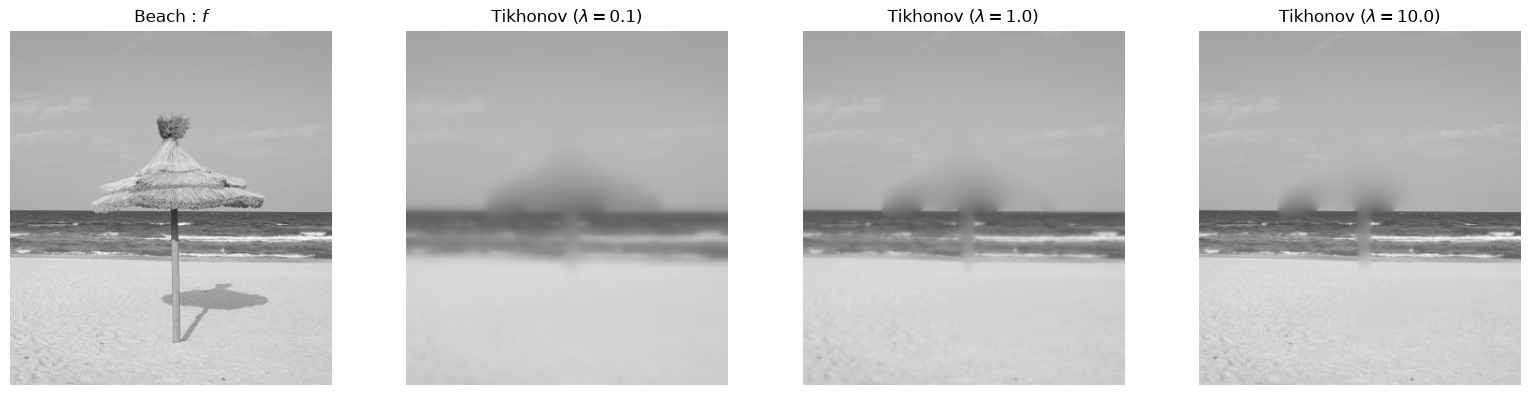

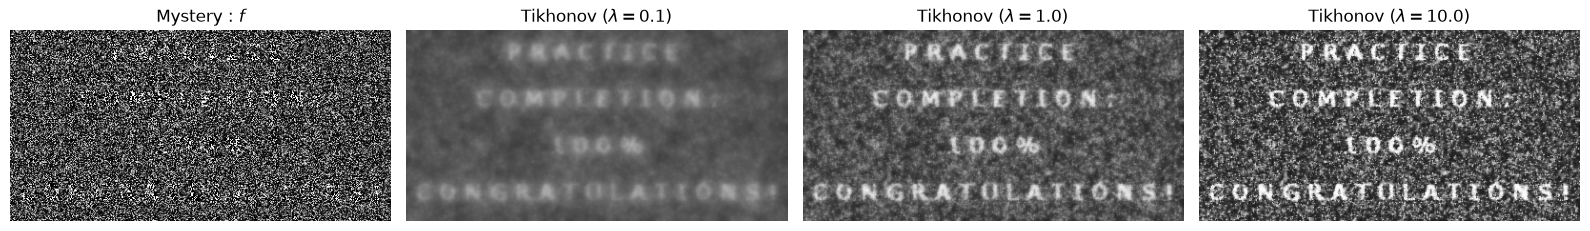

In [29]:
lambdas_inp = [0.1, 1.0, 10.0]
K_inp = 5000

for name, Im, Mask in [("Parrot", Im_parrot, Mask_parrot),
                       ("Beach", Im_beach, Mask_beach),
                       ("Mystery", Im_mystery, Mask_mystery)]:
    fig, axes = plt.subplots(1, len(lambdas_inp) + 1, figsize=(16, 4))
    axes[0].imshow(Im, cmap='gray', **bounds)
    axes[0].set_title(f"{name} : $f$")
    axes[0].axis('off')

    for i, lamb in enumerate(lambdas_inp):
        u_inp = Inpainting_Tikhonov(Im, Mask, tau=1.0 / (lamb + 4.0), K=K_inp, lamb=lamb)
        axes[i+1].imshow(u_inp, cmap='gray', **bounds)
        axes[i+1].set_title(f"Tikhonov ($\\lambda = {lamb}$)")
        axes[i+1].axis('off')

    plt.tight_layout()
    plt.show()

#### Tests : TV, déconvolution et inpainting

In [30]:
# Tests de la TV, de la déconvolution et de l'inpainting (petite image, graine fixée)
rng = np.random.default_rng(1)
f_t = 255 * rng.random((24, 30))
M_t = (rng.random(f_t.shape) > 0.3).astype(np.float64)
G_t = gaussian_kernel(size=5, sigma=1.5)
G_t = G_t / G_t.sum()
eps_t, lamb_t = 5.0, 0.5
ident, masque, flou = (lambda u: u), (lambda u: M_t * u), (lambda u: convolve(u, G_t))

def tv_lisse(u):
    g = gradient(u)
    return np.sum(np.sqrt(g[0]**2 + g[1]**2 + eps_t**2))

def energie(u, A):
    return lamb_t / 2 * np.sum((A(u) - A(f_t) if A is masque else A(u) - f_t)**2) + tv_lisse(u)

def grad_energie(u, A):      # A est auto-adjoint dans les trois cas
    r = A(u) - (M_t * f_t if A is masque else f_t)
    return lamb_t * A(r) - div(tv_flux(u, eps_t))

# 1. G est auto-adjoint (Q8)
u_t, v_t = rng.standard_normal(f_t.shape), rng.standard_normal(f_t.shape)
assert abs(np.sum(convolve(u_t, G_t) * v_t) - np.sum(u_t * convolve(v_t, G_t))) < 1e-9

# 2. Le gradient des trois énergies est juste (différences finies centrées)
for A in (ident, flou, masque):
    d = rng.standard_normal(f_t.shape)
    df = (energie(f_t + u_t + 1e-4 * d, A) - energie(f_t + u_t - 1e-4 * d, A)) / 2e-4
    assert abs(df - np.sum(grad_energie(f_t + u_t, A) * d)) < 1e-4 * (1 + abs(df))

# 3. Chaque descente arrive à un point critique (gradient nul) et l'énergie décroît
tau_t = 1.0 / (lamb_t + 8.0 / eps_t)
descentes = {
    "Denoise_TV": (ident, lambda K: Denoise_TV(f_t, K, lamb_t, eps=eps_t, tau=tau_t, conv_crit=0)),
    "Deconvolution_TV": (flou, lambda K: Deconvolution_TV(f_t, G_t, tau_t, eps_t, K, lamb_t)),
    "Inpainting_TV": (masque, lambda K: Inpainting_TV(f_t, M_t, tau_t, eps_t, K, lamb_t)),
}
for nom, (A, descente) in descentes.items():
    E = [energie(descente(K), A) for K in (0, 1, 10, 100, 1000)]
    assert all(b <= a + 1e-6 for a, b in zip(E, E[1:])), (nom, E)
    g0, g1 = np.abs(grad_energie(f_t, A)).max(), np.abs(grad_energie(descente(20000), A)).max()
    assert g1 < 1e-3 * max(g0, 1.0), (nom, g0, g1)

# 4. Cas limites : sans flou ni masque, on retrouve le débruitage TV
u_ref = Denoise_TV(f_t, 200, lamb_t, eps=eps_t, tau=tau_t, conv_crit=0)
assert np.allclose(Deconvolution_TV(f_t, np.array([[1.0]]), tau_t, eps_t, 200, lamb_t), u_ref)
assert np.allclose(Inpainting_TV(f_t, np.ones_like(f_t), tau_t, eps_t, 200, lamb_t), u_ref)
assert abs(u_ref.mean() - f_t.mean()) < 1e-9                   # le débruitage conserve la moyenne
assert np.allclose(Inpainting_TV(f_t, 255 * M_t, tau_t, eps_t, 50, lamb_t),
                   Inpainting_TV(f_t, M_t, tau_t, eps_t, 50, lamb_t))   # masque 0/255 ou 0/1

# 5. Inpainting Tikhonov : condition d'optimalité, donc Delta u = 0 dans les trous
u_ik = Inpainting_Tikhonov(f_t, M_t, 1.0 / (lamb_t + 4.0), 20000, lamb_t, conv_crit=0)
res_ik = lamb_t * M_t * (u_ik - f_t) - laplacian(u_ik)
assert np.abs(res_ik).max() < 1e-6, np.abs(res_ik).max()
assert np.abs(laplacian(u_ik)[M_t == 0]).max() < 1e-6
print("TV, déconvolution, inpainting : OK")

TV, déconvolution, inpainting : OK


## 13

Sur papier : voir `TP2_questions_papier.pdf`.

## 14

### Conditions d'optimalité

On minimise $J_\lambda(u) = \frac{\lambda}{2}\|u - f\|^2 + \sum_{x} \phi(\|\nabla u(x)\|)$.

Pour un $\phi$ dérivable, le gradient du terme de régularisation est
$\nabla J_R(u) = -\operatorname{div}\left( \frac{\phi'(\|\nabla u\|)}{\|\nabla u\|} \nabla u \right)$,
donc la condition d'optimalité (Euler-Lagrange) s'écrit :

$$\lambda (u - f) - \operatorname{div}\left( \frac{\phi'(\|\nabla u\|)}{\|\nabla u\|} \nabla u \right) = 0$$

| | $\phi(\xi)$ | $\phi'(\xi)$ | $\phi'(\xi)/\xi$ | Condition d'optimalité |
|---|---|---|---|---|
| TV lissée | $\sqrt{\xi^2 + 1}$ | $\frac{\xi}{\sqrt{\xi^2+1}}$ | $\frac{1}{\sqrt{\xi^2+1}}$ | $\lambda(u-f) - \operatorname{div}\left(\frac{\nabla u}{\sqrt{\|\nabla u\|^2+1}}\right) = 0$ |
| $\phi_1$ | $\frac{\xi^2}{1+\xi^2}$ | $\frac{2\xi}{(1+\xi^2)^2}$ | $\frac{2}{(1+\xi^2)^2}$ | $\lambda(u-f) - \operatorname{div}\left(\frac{2\nabla u}{(1+\|\nabla u\|^2)^2}\right) = 0$ |
| $\phi_2$ | $\log(1+\xi^2)$ | $\frac{2\xi}{1+\xi^2}$ | $\frac{2}{1+\xi^2}$ | $\lambda(u-f) - \operatorname{div}\left(\frac{2\nabla u}{1+\|\nabla u\|^2}\right) = 0$ |

Remarque : $\phi_1$ et $\phi_2$ ne sont **pas convexes** (concaves pour $\xi$ grand), donc cette condition est seulement nécessaire : la descente de gradient converge vers un point critique qui dépend de l'initialisation $u^0 = f$.

En pratique, les pixels valent entre 0 et 255, donc on remplace $\xi$ par $\xi/\varepsilon$ (fonction $\varepsilon^2\phi(\xi/\varepsilon)$) : $\varepsilon$ fixe le seuil de contraste à partir duquel un gradient est considéré comme un contour.

In [31]:
def Denoise_g1(f, K, lamb, eps, tau, conv_crit=1e-5):
    """
    Débruitage avec phi_1(xi) = xi^2 / (1 + xi^2)   (non convexe)
    On utilise la version mise à l'échelle  eps^2 * phi_1(|grad u| / eps) :
    eps joue le rôle de seuil de contraste (gradients >> eps = contours conservés).

    Descente de gradient :
        u^{k+1} = u^k + tau * ( lamb * (f - u^k) + div( w1(|grad u^k|) * grad u^k ) )
    avec  w1(t) = phi_1'(s) / s = 2 / (1 + s^2)^2,   s = t / eps.
    Stable pour tau < 2 / (lamb + 16)  (w1 <= 2 et constante du laplacien = 8).
    """
    weight = lambda g2: 2.0 / (1.0 + g2 / eps**2)**2   # phi_1'(s) / s,  s = |grad u| / eps
    return Denoise_weighted(f, K, lamb, tau, weight, conv_crit)

In [32]:
def Denoise_g2(f, K, lamb, eps, tau, conv_crit=1e-5):
    """
    Débruitage avec phi_2(xi) = log(1 + xi^2)   (non convexe)
    Version mise à l'échelle  eps^2 * phi_2(|grad u| / eps).

    Descente de gradient :
        u^{k+1} = u^k + tau * ( lamb * (f - u^k) + div( w2(|grad u^k|) * grad u^k ) )
    avec  w2(t) = phi_2'(s) / s = 2 / (1 + s^2),   s = t / eps.
    (c'est exactement le coefficient de diffusion de Perona-Malik)
    Stable pour tau < 2 / (lamb + 16).
    """
    weight = lambda g2: 2.0 / (1.0 + g2 / eps**2)   # phi_2'(s) / s,  s = |grad u| / eps
    return Denoise_weighted(f, K, lamb, tau, weight, conv_crit)

#### Comparaison `Denoise_TV`, `Denoise_g1`, `Denoise_g2`

TV        eps=1.0   RMSE selon lambda [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8] : ['14.6', '11.5', '13.5', '16.7', '22.4', '26.7', '27.9']
$\phi_1$  eps=20.0  RMSE selon lambda [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8] : ['18.5', '15.9', '14.3', '14.1', '15.2', '20.3', '24.2']
$\phi_1$  eps=40.0  RMSE selon lambda [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8] : ['30.5', '27.4', '23.9', '21.5', '16.8', '12.4', '12.2']
$\phi_1$  eps=50.0  RMSE selon lambda [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8] : ['32.5', '29.0', '25.7', '23.8', '19.5', '13.6', '12.2']
$\phi_2$  eps=5.0   RMSE selon lambda [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8] : ['16.5', '13.4', '12.4', '13.4', '20.0', '26.5', '27.9']
$\phi_2$  eps=10.0  RMSE selon lambda [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8] : ['26.4', '21.4', '16.6', '14.7', '11.8', '16.1', '21.5']
$\phi_2$  eps=15.0  RMSE selon lambda [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8] : ['30.0', '25.9', '21.9', '19.2', '14.1', '11.4', '14.2']


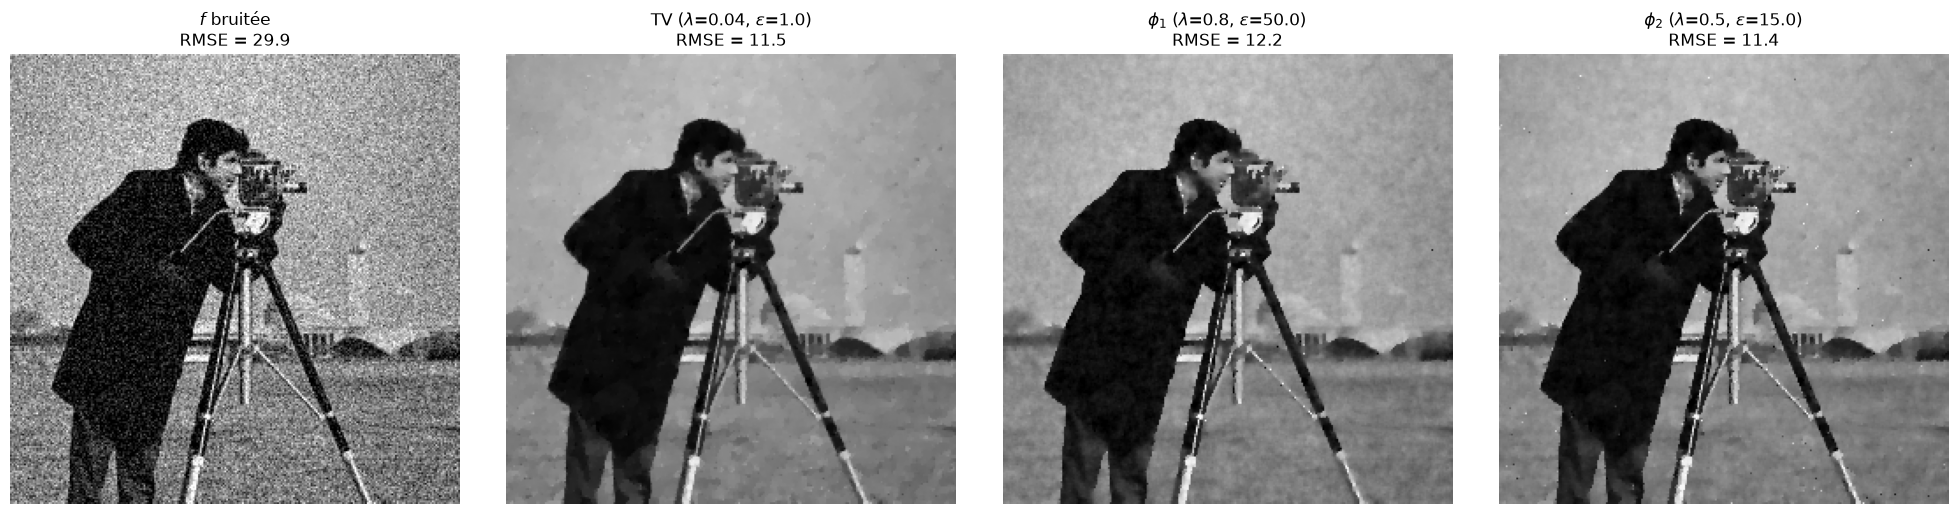

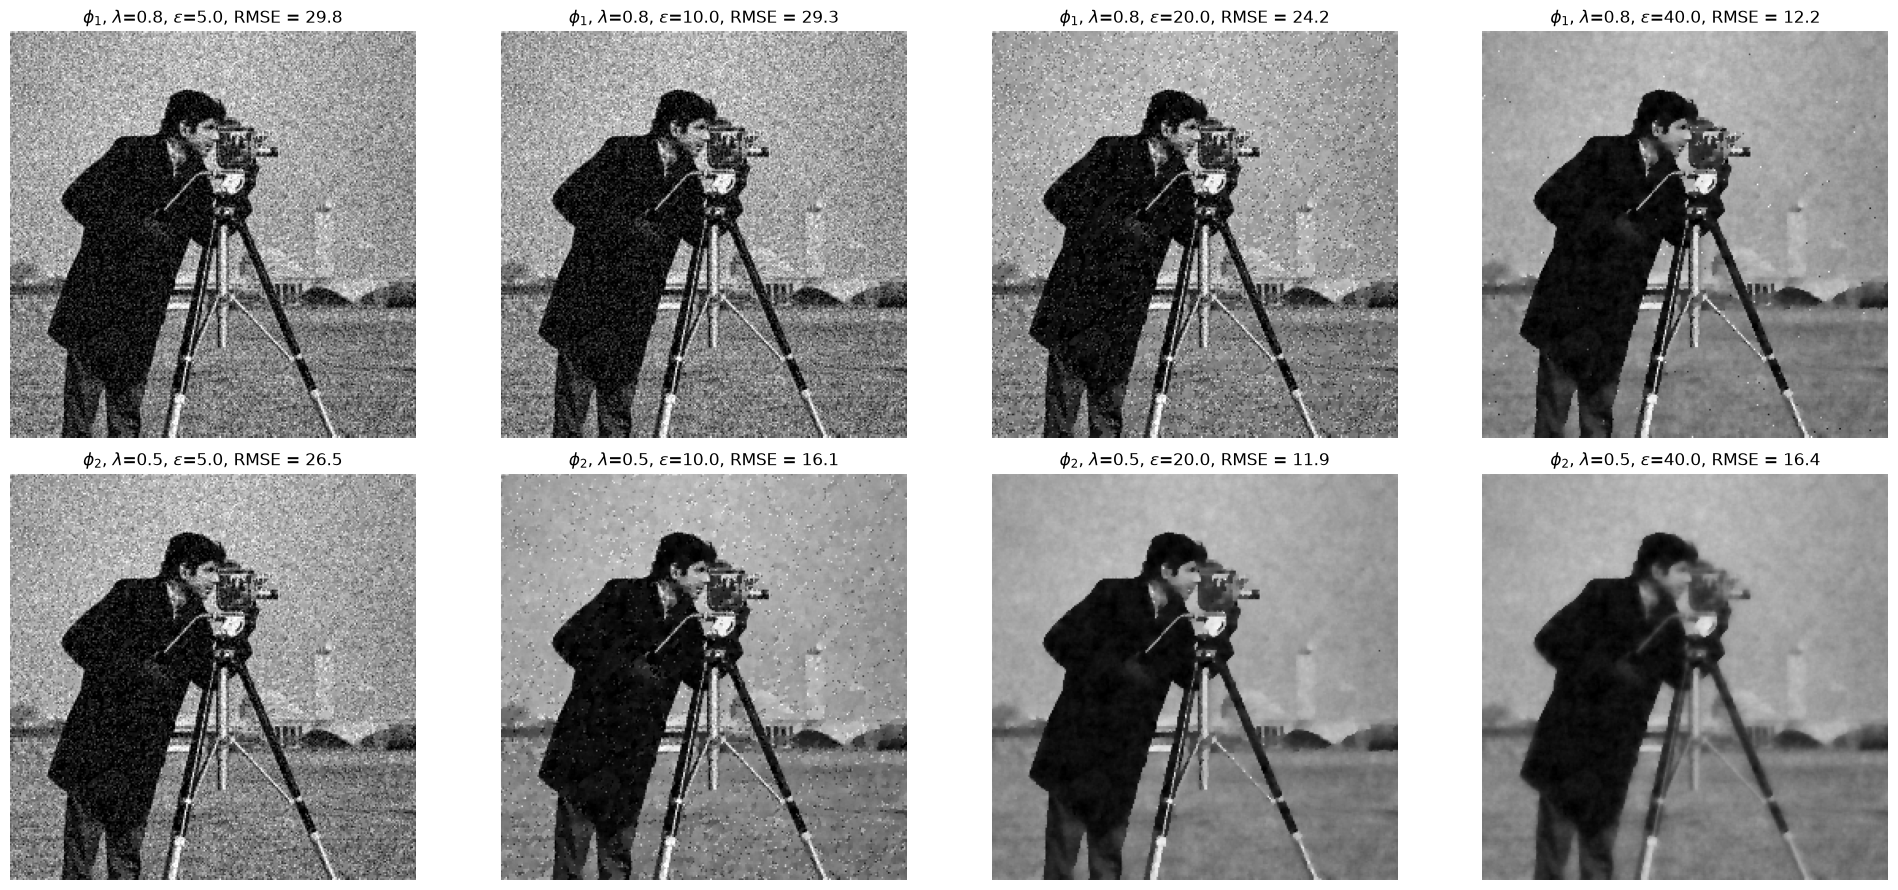

In [33]:
# Comparaison à réglages égaux : même K, même critère d'arrêt (aucun), et (lambda, eps) réglés pour chaque méthode.
K_cmp = 3000
tau_cmp = 0.1          # < 2 / (lamb + 16) : stable pour les trois méthodes
lambdas_cmp = [0.02, 0.04, 0.07, 0.1, 0.2, 0.5, 0.8]
eps_grid = {"TV": [1.0], "$\\phi_1$": [20.0, 40.0, 50.0], "$\\phi_2$": [5.0, 10.0, 15.0]}
methods = {"TV": Denoise_TV, "$\\phi_1$": Denoise_g1, "$\\phi_2$": Denoise_g2}

best = {}              # nom -> (rmse, lambda, eps, u)
for name, fn in methods.items():
    for e in eps_grid[name]:
        errs = []
        for l in lambdas_cmp:
            u = fn(Im_noised, K=K_cmp, lamb=l, eps=e, tau=tau_cmp, conv_crit=0)
            errs.append(rmse(u, Im_data))
            if name not in best or errs[-1] < best[name][0]:
                best[name] = (errs[-1], l, e, u)
        print(f"{name:9s} eps={e:<5} RMSE selon lambda {lambdas_cmp} :", [f"{x:.1f}" for x in errs])

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
axes[0].imshow(Im_noised, cmap='gray', **bounds)
axes[0].set_title(f"$f$ bruitée\nRMSE = {rmse(Im_noised, Im_data):.1f}")
axes[0].axis('off')
for ax, (name, (err, l, e, u)) in zip(axes[1:], best.items()):
    ax.imshow(u, cmap='gray', **bounds)
    ax.set_title(f"{name} ($\\lambda$={l}, $\\varepsilon$={e})\nRMSE = {err:.1f}")
    ax.axis('off')
plt.tight_layout()
plt.show()

# Influence de eps (seuil de contraste), lambda fixé au meilleur de chaque méthode
eps_list = [5.0, 10.0, 20.0, 40.0]
fig, axes = plt.subplots(2, len(eps_list), figsize=(20, 9))
for i, name in enumerate(["$\\phi_1$", "$\\phi_2$"]):
    l = best[name][1]
    for j, e in enumerate(eps_list):
        u = methods[name](Im_noised, K=K_cmp, lamb=l, eps=e, tau=tau_cmp, conv_crit=0)
        axes[i, j].imshow(u, cmap='gray', **bounds)
        axes[i, j].set_title(f"{name}, $\\lambda$={l}, $\\varepsilon$={e}, RMSE = {rmse(u, Im_data):.1f}")
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()

### Commentaires

- **Qualité** (bruit $\sigma=30$, RMSE de $f$ ≈ 29.9, mêmes $K=3000$ et critère d'arrêt pour les trois) : une fois $(\lambda, \varepsilon)$ réglés pour chaque méthode, la TV lissée ($\lambda=0.04$, RMSE ≈ 11.5) et $\phi_2$ ($\lambda=0.5$, $\varepsilon=15$, ≈ 11.4) sont **à égalité**, devant $\phi_1$ ($\lambda=0.8$, $\varepsilon=50$, ≈ 12.2). Attention : avec $\lambda$ trop petit (0.01), s'arrêter tôt joue le rôle d'une régularisation et peut fausser le classement.
- **Préservation des contours** : le poids $\phi'(\xi)/\xi$ décroît en $1/\xi$ pour TV, en $1/\xi^2$ pour $\phi_2$ et en $1/\xi^4$ pour $\phi_1$. Plus il décroît vite, moins on diffuse à travers les forts gradients : les contours restent nets, les zones plates sont lissées.
- **Rôle de $\varepsilon$** : c'est un seuil de contraste. Trop petit, le bruit est vu comme des contours et n'est pas retiré ; trop grand, les vrais contours sont lissés. Le bon $\varepsilon$ n'est pas le même pour $\phi_1$ et $\phi_2$, et il dépend du niveau de bruit.
- **Non-convexité** : contrairement à Tikhonov et à la TV, $J_\lambda$ n'est plus convexe. Il n'y a pas d'unicité du minimiseur, le résultat dépend de l'initialisation ($u^0 = f$) et du nombre d'itérations. $\phi_1$ est bornée (elle « sature » à 1) : elle pénalise à peu près pareil tous les grands sauts, ce qui favorise des images constantes par morceaux.
- **Rôle de $\lambda$** : il équilibre attache aux données et régularisation, et **compte autant que $\varepsilon$** (par exemple $\phi_2$, $\varepsilon=15$ : RMSE ≈ 30 pour $\lambda=0.02$, ≈ 11.4 pour $\lambda=0.5$). Les deux se règlent ensemble : plus $\varepsilon$ est grand, plus le $\lambda$ optimal est grand.